<!-- solution file -->
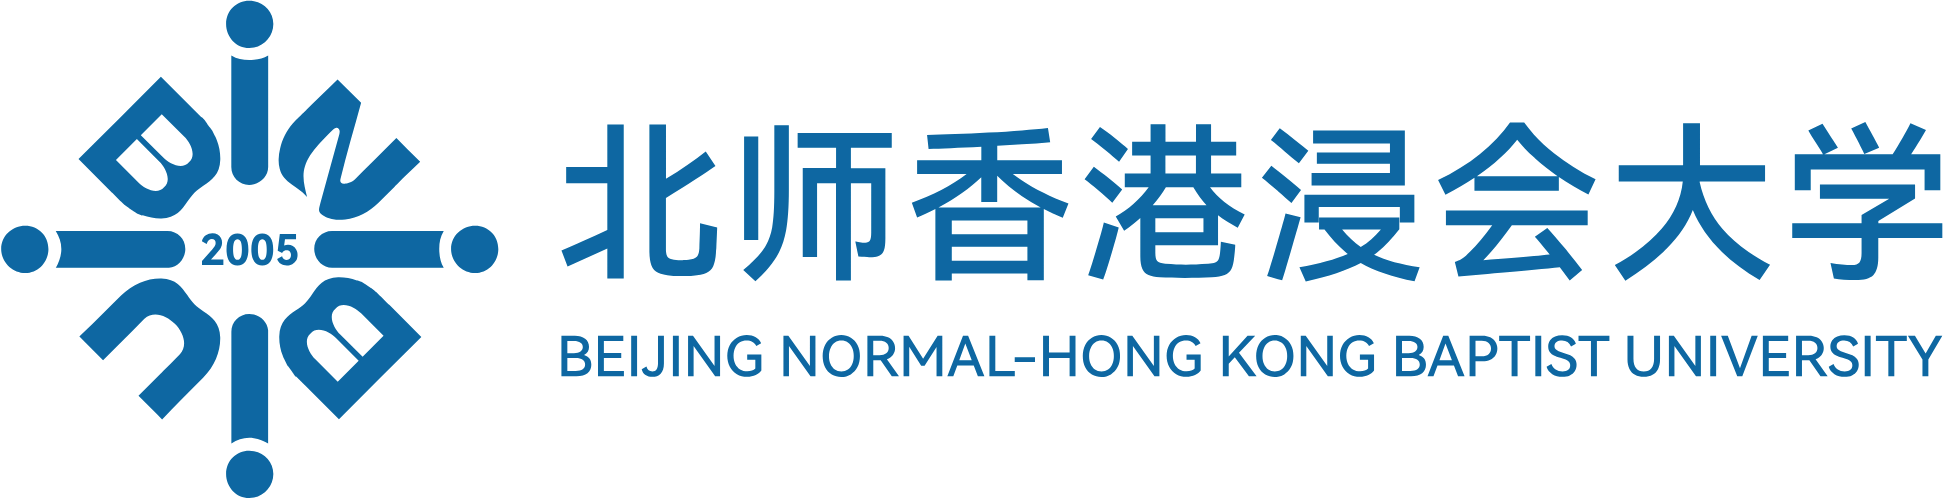

# NUMERICAL AND SIMULATION TECHNIQUES IN FINANCE (FINM4053)
## ASSIGNMENT 3 SOLUTION &nbsp;&nbsp;&nbsp;&nbsp; \| &nbsp;&nbsp;&nbsp;&nbsp; 2025/11/24
<!-- solution file -->
---

### **Question 1**  &nbsp;&nbsp; (10 points)
<!-- solution file -->
**1a)** The **logistic distribution** with location parameter $\mu\in\mathbb{R}$ and scale parameter $\sigma>0$ is defined by the cumulative distribution function
$$F(x)=\frac{1}{1+\exp(-(x-\mu)/\sigma)}$$
for any $x\in\mathbb{R}$. Write a Python function to generate $M$ simulations of the logistic distribution by the inverse transform sampling method. The three input parameters of the Python function are $M$, $\mu$ and $\sigma$. [5 points]

**1b)** The **Lomax distribution** with shape parameter $p>0$ and scale parameter $\sigma>0$ is defined by the probability distribution function
$$f(x)=\frac{p}{\sigma}\left(1+\frac{x}{\sigma}\right)^{-(p+1)}$$
for any $x\geq0$ (and zero otherwise). Find the cumulative distribution function of the Lomax distribution (pay attention to the constant term) and explain how to simulate the Lomax distribution by inverse transform sampling. Implement this method in Python; the three input parameters of the Python function are the number of simulations $M$, the shape parameter $p$ and the scale parameter $\sigma$. [5 points]

### **Answer 1a)**
<!-- solution file -->
The inverse of $F$ is defined by 
$$F^{-1}(u)=\mu-\sigma\log\left(\frac{1}{u}-1\right)$$
for any $u\in(0,1)$. According to the inverse transform sampling method, if $U$ is a standard uniform random variable, then the random variable $F^{-1}(U)$ follows a logistic distribution.

In [4]:
from scipy.stats import uniform
def logistic_rvs(M,mu,sigma):
    return mu-sigma*np.log(1/uniform.rvs(size=M)-1)

print(logistic_rvs(24,5.0,2.0))

[ 2.78627881  9.77405511  3.08638242  5.79606228  3.80546544  3.47155769
  0.56283785  4.65595607  8.97444449  7.92813534 -3.96114216  6.55554894
  3.57122396  4.96557598  2.09694708 -3.89259917  8.71081134  6.5163284
  0.08841846 -2.2581118   1.94331245  1.41704243  4.65196726  2.28652076]


### **Answer 1b)**
<!-- solution file -->
Integrate $f$ to obtain the CDF of a Lomax distribution:  
$$F(x)=1-\left(1+\frac{x}{\sigma}\right)^{-p}$$
The constant term of this antiderivative is chosen such that $F(0)=0$ and $F(x)\underset{x\rightarrow\infty}{\longrightarrow}1$  
The inverse of $F$ is defined by 
$$F^{-1}(u)=\sigma\left(\left(\frac{1}{1-u}\right)^\frac{1}{p}-1\right)$$
for any $u\in(0,1)$. According to the inverse transform sampling method, if $U$ is a standard uniform random variable, then the random variable $F^{-1}(U)$ follows a Lomax distribution. As usual, $1-U$ can be replaced by $U$ because these two random variables have the same distribution.

In [7]:
from scipy.stats import uniform
def lomax_rvs(M,p,sigma):
    return sigma*((1/uniform.rvs(size=M))**(1/p)-1)

print(lomax_rvs(24,2.0,3.0))

[ 3.80562421  0.28981626  0.24375513  0.455591    2.00071364  0.94155285
  0.46730885  1.46585338  3.68530767  9.52483187  4.54187542  6.84802913
  2.23096929  1.36552795  1.28154764 11.77943327  1.74710761  5.21437009
  0.70410156  0.27953799  3.41097634 16.09882806  3.57555689  2.17704853]


### **Question 2**  &nbsp;&nbsp; (15 points)
<!-- solution file -->
Let $\mathcal{D}\subseteq\mathbb{R}$ be a real domain, let $X$ be a continuous random variables taking values in $\mathcal{D}$, let $f_{\!X}$ be the density of $X$ and let $g:\mathcal{D}\rightarrow\mathbb{R}$ be a real function. The Monte Carlo simulation method can be used to approximate integrals, since
<!-- solution file -->
$$\begin{equation}
\underset{\mathcal{D}}{\int}g(x)f_{\!X}(x)dx=\mathbb{E}\left[g(X)\right]\simeq\frac{1}{M}\sum_{m=1}^{M}g(X_{m})
\end{equation}$$
where $X_1, X_2, \ldots, X_M$ are $M$ independent and identically distributed simulations of $X$. Use this equation to estimate the following integrals by Monte Carlo simulations:
<!-- solution file -->
$$\begin{align*}
 & I_{1}:=4\int_{0}^{1}\sqrt{1-u^{2}}du\\
\\
 & I_{2}:=\int_{0}^{\infty}t^{\frac{3}{2}}e^{-t}dt\\
\\
 & I_{3}:=\int_{-\infty}^{\infty}(1+x^{2})^2e^{-x^{2}}dx
\end{align*}$$
<!-- solution file -->
For each integral, write down the density $f_{\!X}$ and the integrand $g$ that you are using.

### **Answer 2**
<!-- solution file -->
Let $f_{U}(u)=\mathbf{1}\{0\leq u\leq1\}$ be the density of a standard uniform random variable $U$. One can see that $I_1=\mathbb{E}\left[g_1(U)\right]$ where $g_1(u)=4\sqrt{1-u^{2}}$.  
Let $f_{\!E}(t)=e^{-t}\mathbf{1}\{t>0\}$ be the density of a standard exponential random variable $E$. One can see that $I_2=\mathbb{E}\left[g_2(E)\right]$ where $g_2(t)=t^\frac{3}{2}$.  
The density of a Gaussian random variable is given by $f_{\mu,\sigma}(x)=\frac{1}{\sigma\sqrt{2\pi}}\exp\left(-\frac{1}{2}\left(\frac{x-\mu}{\sigma}\right)^{2}\right)$. If we set $\mu=0$ and $\sigma=1/\sqrt{2}$, then we can see that $I_3=\mathbb{E}\left[g_3(N)\right]$ where $g_3(x)=\sqrt{\pi}(1+x^2)^2$ and $N$ is a Gaussian random variable with mean $\mu=0$ and standard deviation $\sigma=1/\sqrt{2}$.

In [11]:
from scipy.stats import uniform, expon, norm
M = 10**7
I1 = np.mean( 4.0*np.sqrt( 1.0 - uniform.rvs(size=M)**2.0 ) )
I2 = np.mean( expon.rvs(size=M)**(3/2) )
I3 = np.mean( np.sqrt(np.pi) * (1+norm.rvs(size=M, scale=1.0/np.sqrt(2.0))**2)**2 )
print( (I1 , np.pi ) ) # MC estimator of I1 compared to exact value
print( (I2 , np.sqrt(np.pi)*3.0/4.0 ) ) # MC estimator of I2 compared to exact value
print( (I3 , np.sqrt(np.pi)*11.0/4.0 ) ) # MC estimator of I3 compared to exact value

(3.1416769605059915, 3.141592653589793)
(1.329102093763411, 1.329340388179137)
(4.874813057784303, 4.874248089990169)


### **Question 3**  &nbsp;&nbsp; (10 points)
<!-- solution file -->
Estimate $\mathbb{E}\left[\exp(G)\right]$, where $G$ is a standard Gaussian random variable, by Monte Carlo simulations.  
Can you estimate $\mathbb{E}\left[\exp(G^2)\right]$ by Monte Carlo simulations? Explain.

### **Answer 3**
<!-- solution file -->
$M_G(t):=\mathbb{E}\left[\exp(tG)\right]$, $t\in\mathbb{R}$ is the moment generating function of a Gaussian random variable. If $G\sim\mathcal{N}(\mu,\sigma^2)$, then $M_G(t) = \exp({\mu}t+\sigma^2t^2/2)$. For a standard Gaussian random variable, $M_G(1)=\sqrt{e}$, and a Monte Carlo estimator is given by $\frac{1}{M}\sum_{m=1}^{M}\exp(G_{m})$, where $G_1, G_2, \ldots, G_M$ are i.i.d. standard Gaussian simulations.

In [15]:
from scipy.stats import norm
M = 10**7
print( ( np.mean( np.exp( norm.rvs(size=M) ) ) , np.exp(0.5) ) ) # MC estimator compared to exact value

(1.6481990494499463, 1.6487212707001282)


Regarding $\mathbb{E}\left[\exp(G^2)\right]$, one can show that  
$$\mathbb{E}\left[\exp(G^2)\right]=\int_{-\infty}^\infty \exp(x^2)\times\frac{1}{\sqrt{2\pi}}\exp\!\left(-\frac{x^2}{2}\right)
=\frac{1}{\sqrt{2\pi}}\int_{-\infty}^\infty \exp\!\left(\frac{x^2}{2}\right)=\infty$$
Since the expectation $\mathbb{E}\left[\exp(G^2)\right]$ does not converge, the Monte Carlo approach cannot be applied to estimate it. If we still try to compute the Monte Carlo estimator $\frac{1}{M}\sum_{m=1}^{M}\exp(G_{m}^2)$, where $G_1, G_2, \ldots, G_M$ are i.i.d. standard Gaussian simulations, the outcome will simply be a meaningless large random number, as this average does not converge.

In [16]:
print( np.mean( np.exp( norm.rvs(size=M)**2 ) ) ) # does not converge

1696051.600482728


### **Question 4**  &nbsp;&nbsp; (15 points)
<!-- solution file -->
The *Frank copula* with parameter $\theta\in\mathbb{R}{\backslash}\{0\}$ is defined by the formula
$$\begin{equation}
\mathcal{C}(u,v):=-\frac{1}{\theta}\log\left(1+\frac{(e^{-\theta u}-1)(e^{-\theta v}-1)}{e^{-\theta}-1}\right)
\end{equation}$$ 
**4a)** Explain how to simulate a bivariate uniform random vector $(U,V)$ with joint distribution given by Frank's copula by *conditional sampling*. Derive all the necessary mathematical formulas. [10 points]

**4b)** Implement your conditional sampling algorithm in Python. Generate $M=1000$ simulations from Frank's copula with $\theta=20$, and show the histogram. [5 points]

### **Answer 4a**
<!-- solution file -->
To simulate $(U,V)$ according to Frank's copula, we first simulate $U$ as a uniform random variable, then simulate $V$ according to the conditional CDF $c_U(.)=\frac{\partial\mathcal{C}}{\partial u}(U,.)$, using inverse transform sampling. One can show that
$$c_u(v)=\frac{\partial\mathcal{C}}{\partial u}(u,v)=\left(-\frac{1}{\theta}\right)\left((-\theta)e^{-\theta u}\frac{e^{-\theta v}-1}{e^{-\theta}-1}\right)\frac{1}{1+\frac{(e^{-\theta u}-1)(e^{-\theta v}-1)}{e^{-\theta}-1}}=\frac{e^{-\theta u}}{\frac{e^{-\theta}-1}{e^{-\theta v}-1}+e^{-\theta u}-1}$$
and the inverse of this conditional CDF is given by
$$c_{u}^{-1}(w)=-\frac{1}{\theta}\log\left(1+\frac{e^{-\theta}-1}{1+e^{-\theta u}\left(\frac{1}{w}-1\right)}\right)$$<!-- solution file -->
(set $c_u(v)=w$ and solve for $v$)  
To sum up, simulate two independent uniforms $U_1$ and $U_2$, then set $U=U_1$ and $V=c_{U_1}^{-1}(U_2)$.

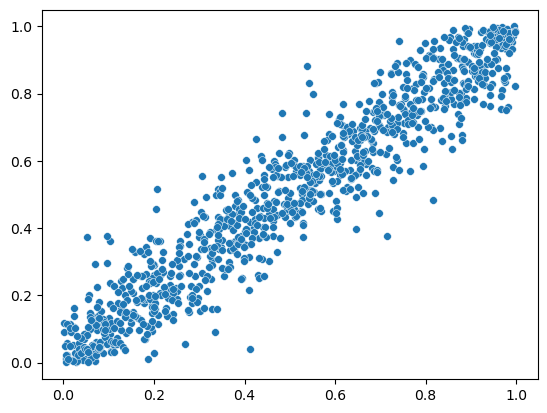

In [2]:
import numpy as np
from scipy.stats import uniform
theta = 20
M = 1000
U1 = uniform.rvs(size=M)
U2 = uniform.rvs(size=M)
U = U1
V = -1/theta * np.log( 1 + (np.exp(-theta)-1) / ( 1+np.exp(-theta*U1)*(1/U2-1) ) )

import matplotlib.pyplot as plt
import seaborn as sns
sns.scatterplot(x=U, y=V, s=125, marker=".", linewidth=0.35)
plt.show()